# Drone failure forecasting: survival analysis

Cox and AFT gradient boosting (XGBoost) on right-censored flight hours.

1. Setup
2. Data and time split
3. Training
4. Predicted survival and hazard vs observed
5. Model quality
6. Risk factors (SHAP)
7. Remaining useful life
8. Artifacts for the dashboards

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import copy
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sksurv.nonparametric import kaplan_meier_estimator

from utils import (
    SCALAR_METRICS,
    Model,
    bootstrap_compare,
    calibration_curve,
    evaluate,
    evaluation_times,
    fit_categories,
    hazard_bandwidth,
    observed_hazard,
    population_hazard,
    remaining_life,
    tune,
)

In [2]:
MODELS_DIR = "./models"
ARTIFACTS_DIR = "./artifacts"

RUL_WINDOW = 100  # look-ahead window of the failure probability, flight hours

In [3]:
FEATURES = [
    "model",
    "environment",
    "is_refurbished",
    "initial_battery_cycles",
    "firmware_major",
    "maintenance_interval_h",
    "operator_experience_yrs",
    "daily_utilization_h",
    "avg_flight_min",
    "avg_payload_kg",
    "payload_ratio",
    "mean_temp_c",
    "avg_humidity_pct",
    "avg_wind_ms",
    "hard_landings_per_100h",
    "mean_vibration_g",
]

CAT_FEATURES = ["model", "environment", "is_refurbished", "firmware_major"]

## 2. Data and time split

Drones are split by commissioning date: the first 70% train, the next 10% validation, the last 20% test. The printed rows are the split shares and the failure share per split.

A censored drone is **in service** if its flight log reaches the data cut-off: `commission_date + duration_h / daily_utilization_h` days is the last day it was observed. Censored drones last seen earlier left the fleet (sold, lost, retired). They stay in the data as censored observations but get no remaining-life forecast.

The split is by cohort, not by calendar time: training drones are followed up to the cut-off, i.e. after the test drones were commissioned. Nothing in these data depends on calendar time, so this is harmless here; with seasonal or fleet-wide effects it would leak the future into training.

In [4]:
df = pd.read_csv("data/drone_survival.csv")

In [5]:
df.head()

,drone_id,model,environment,commission_date,is_refurbished,initial_battery_cycles,firmware_major,maintenance_interval_h,operator_experience_yrs,daily_utilization_h,...,avg_payload_kg,payload_ratio,mean_temp_c,avg_humidity_pct,avg_wind_ms,hard_landings_per_100h,mean_vibration_g,duration_h,event,failure_mode
0,DR-000000,hexa_heavy,urban,2024-08-12,False,22,5,50,3.93,3.42,...,3.886,0.389,-0.1,65.9,4.68,2.60,0.507,224.02,0,censored
1,DR-000001,quad_heavy,coastal,2025-01-06,False,25,4,50,3.99,1.06,...,4.166,0.833,23.7,65.2,5.16,2.72,0.678,380.54,0,censored
2,DR-000002,fixed_wing_vtol,coastal,2024-08-10,False,2,5,50,3.30,1.66,...,2.278,0.759,23.9,73.8,3.70,1.89,0.424,11.57,1,electronics
3,DR-000003,hexa_heavy,urban,2024-11-05,False,5,3,25,3.34,2.48,...,7.129,0.713,11.2,57.8,3.78,1.00,0.440,1044.08,0,censored
4,DR-000004,quad_light,urban,2025-04-25,False,8,4,200,2.11,1.63,...,0.335,0.335,19.2,54.7,6.20,1.63,0.367,63.67,1,crash


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   drone_id                 5000 non-null   str    
 1   model                    5000 non-null   str    
 2   environment              5000 non-null   str    
 3   commission_date          5000 non-null   str    
 4   is_refurbished           5000 non-null   bool   
 5   initial_battery_cycles   5000 non-null   int64  
 6   firmware_major           5000 non-null   int64  
 7   maintenance_interval_h   5000 non-null   int64  
 8   operator_experience_yrs  5000 non-null   float64
 9   daily_utilization_h      5000 non-null   float64
 10  avg_flight_min           5000 non-null   float64
 11  avg_payload_kg           5000 non-null   float64
 12  payload_ratio            5000 non-null   float64
 13  mean_temp_c              5000 non-null   float64
 14  avg_humidity_pct         5000 non-n

In [7]:
df["commission_date"] = pd.to_datetime(df["commission_date"])

# Last day each drone was observed. For a drone still flying it is the data cut-off;
# a censored drone last seen earlier has left the fleet.
last_seen = df["commission_date"] + pd.to_timedelta(
    df["duration_h"] / df["daily_utilization_h"], unit="D"
)
cutoff = last_seen.max()
df["in_service"] = (df["event"] == 0) & (last_seen > cutoff - pd.Timedelta(days=1))

t_val, t_test = df["commission_date"].quantile([0.70, 0.80])

train = df[df["commission_date"] < t_val]
val = df[(df["commission_date"] >= t_val) & (df["commission_date"] < t_test)]
test = df[df["commission_date"] >= t_test]
cats = fit_categories(train, CAT_FEATURES)

print(len(train) / len(df), len(val) / len(df), len(test) / len(df))
print(train["event"].mean(), val["event"].mean(), test["event"].mean())
print(
    f"Data cut-off {cutoff.date()}: {(df['event'] == 0).sum()} censored drones, "
    f"{df['in_service'].sum()} of them in service"
)

0.6998 0.1 0.2002
0.6630465847384968 0.546 0.44755244755244755
Data cut-off 2025-12-31: 1959 censored drones, 1586 of them in service


## 3. Training

Hyper-parameters: Optuna on the validation Integrated Brier score; early stopping on validation.

The models are then recalibrated for unobserved heterogeneity between drones (`Model.calibrate`). Drones with the same features still differ in durability; the weaker ones fail first, so the survivors of a high-risk group are sturdier than their features suggest. The correction replaces the cumulative hazard $H$ with $\log(1 + v \cdot k \cdot H) / v$, where $v$ is the variance of the hidden durability (gamma frailty); $v = 0$, $k = 1$ changes nothing. It is fitted on out-of-fold predictions for train, so validation and test stay untouched. A model keeps the correction only if its fitted variance is above 0: with $v = 0$ the link is a plain rescaling of the hazard, which this step is not meant to make. Section 7.2 shows what the correction changes.

The fitted models are saved and reloaded to check the round trip.

In [8]:
N_TRIALS = 20

best_cox = tune("cox", train, val, N_TRIALS, FEATURES, CAT_FEATURES)
best_aft = tune("aft", train, val, N_TRIALS, FEATURES, CAT_FEATURES)

[I 2026-11-15 14:23:47,073] A new study created in memory with name: no-name-db695deb-698e-44ea-a16f-a4c304c0bf66


[I 2026-11-15 14:23:47,272] Trial 0 finished with value: 0.16444699142841954 and parameters: {'max_depth': 3, 'eta': 0.13732181501427546, 'min_child_weight': 12.057126287443763, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.7468055921327309, 'reg_lambda': 0.22853255256339203}. Best is trial 0 with value: 0.16444699142841954.
[I 2026-11-15 14:23:47,704] Trial 1 finished with value: 0.1633328090548445 and parameters: {'max_depth': 2, 'eta': 0.1180201220859558, 'min_child_weight': 7.725378389307352, 'subsample': 0.9124217733388136, 'colsample_bytree': 0.7061753482887407, 'reg_lambda': 17.052641538983092}. Best is trial 1 with value: 0.1633328090548445.
[I 2026-11-15 14:23:48,121] Trial 2 finished with value: 0.16432768882386797 and parameters: {'max_depth': 5, 'eta': 0.03657395726919529, 'min_child_weight': 1.8559980846490576, 'subsample': 0.7550213529560301, 'colsample_bytree': 0.7912726728878613, 'reg_lambda': 1.6124278458562613}. Best is trial 1 with value: 0.1633328090548445.

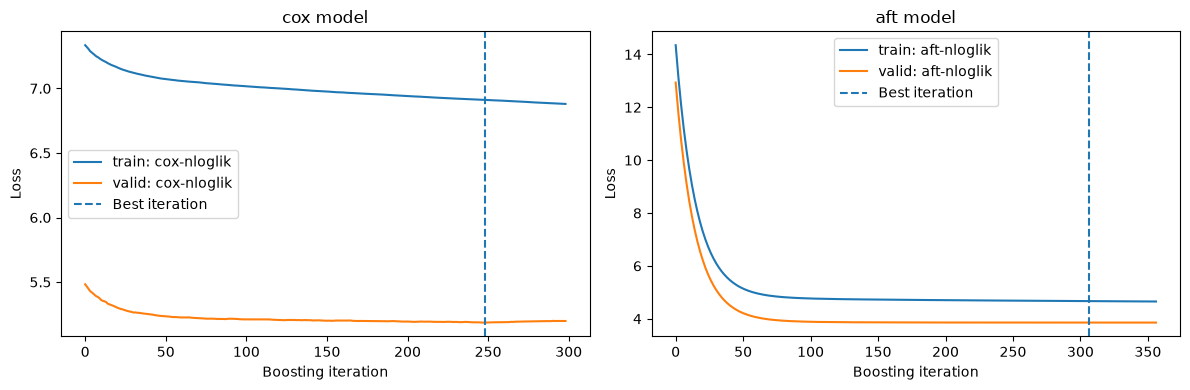

In [9]:
models = {"cox": best_cox, "aft": best_aft}

fig, axes = plt.subplots(1, len(models), figsize=(12, 4))

for ax, (name, model) in zip(axes, models.items()):
    for split, history in model.history.items():
        for metric, values in history.items():
            ax.plot(values, label=f"{split}: {metric}")

    ax.axvline(model.booster.best_iteration, linestyle="--", label="Best iteration")
    ax.set_title(f"{name} model")
    ax.set_xlabel("Boosting iteration")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()

In [10]:
# Recalibrate for unobserved heterogeneity between drones; fitted on out-of-fold
# predictions for train (five refits per model with the tuned parameters)
fitted = {name: model.calibrate(train, val).calibration for name, model in models.items()}

# A variance of 0 means no heterogeneity was found: that model stays as trained
for model in models.values():
    if model.calibration["frailty_variance"] == 0:
        model.calibration = None

pd.DataFrame(fitted).T.assign(
    applied=[model.calibration is not None for model in models.values()]
).round(3)

,frailty_variance,scale,applied
cox,0.267,1.050,True
aft,0.000,1.062,False


In [11]:
os.makedirs(MODELS_DIR, exist_ok=True)

best_cox.save("./models/best_cox.json")
best_aft.save("./models/best_aft.json")

best_cox = Model.load("./models/best_cox.json")
best_aft = Model.load("./models/best_aft.json")

## 4. Predicted survival and hazard vs observed (test)

### 4.1 Survival S(t)

Left: mean predicted curve vs Kaplan-Meier. Right: five random drones.

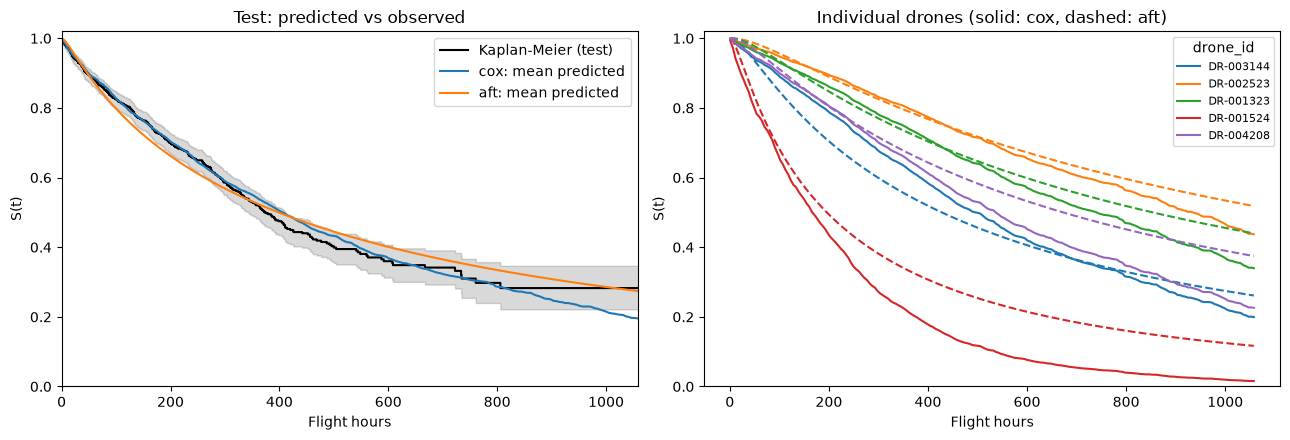

In [12]:
models = {"cox": best_cox, "aft": best_aft}

grid = np.linspace(1, np.quantile(train["duration_h"], 0.95), 200)
curves = {name: model.survival(test, grid) for name, model in models.items()}

km_time, km_surv, km_ci = kaplan_meier_estimator(
    test["event"].astype(bool), test["duration_h"], conf_type="log-log"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.step(km_time, km_surv, where="post", color="black", label="Kaplan-Meier (test)")
ax.fill_between(km_time, km_ci[0], km_ci[1], step="post", color="black", alpha=0.15)
for name, S in curves.items():
    ax.plot(grid, S.mean(axis=0), label=f"{name}: mean predicted")
ax.set(
    title="Test: predicted vs observed",
    xlabel="Flight hours",
    ylabel="S(t)",
    xlim=(0, grid[-1]),
    ylim=(0, 1.02),
)
ax.legend()

ax = axes[1]
idx = np.random.default_rng(0).choice(len(test), size=5, replace=False)
for k, i in enumerate(idx):
    ax.plot(grid, curves["cox"][i], color=f"C{k}", label=test["drone_id"].iloc[i])
    ax.plot(grid, curves["aft"][i], color=f"C{k}", linestyle="--")
ax.set(
    title="Individual drones (solid: cox, dashed: aft)",
    xlabel="Flight hours",
    ylabel="S(t)",
    ylim=(0, 1.02),
)
ax.legend(title="drone_id", fontsize=8)

plt.tight_layout()
plt.show()

### 4.2 Hazard h(t)

Left: predicted fleet hazard vs the kernel-smoothed Nelson-Aalen estimate. Right: the same five drones.

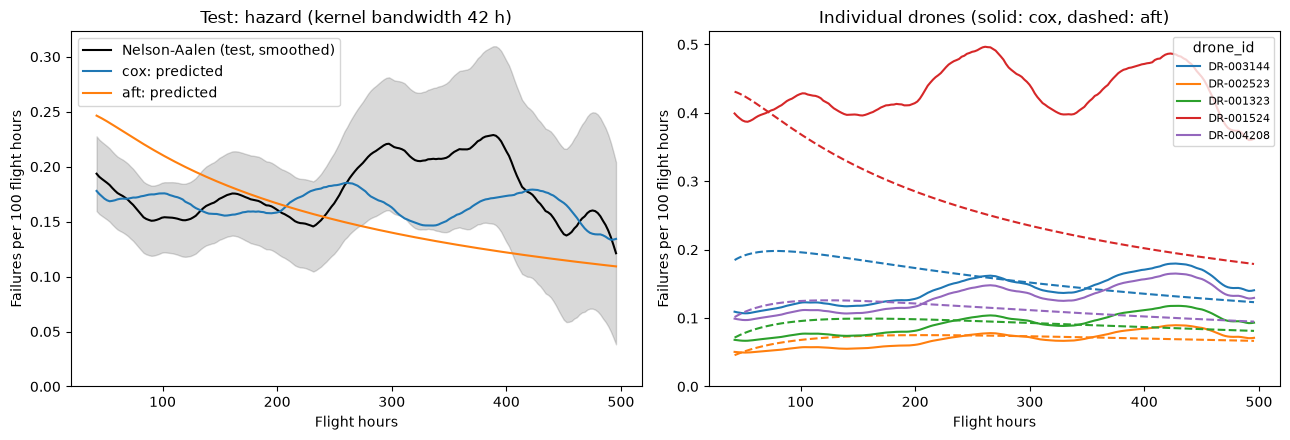

In [13]:
# Hazard h(t): failure rate among drones still flying at t, per 100 flight hours.
# Observed: kernel-smoothed Nelson-Aalen on test. Predicted: survival-weighted mean of
# the individual hazards over the same drones. The kernel loses mass near 0, so the
# grid starts one bandwidth in.
bandwidth = hazard_bandwidth(test["duration_h"], test["event"])
hz_grid = np.linspace(bandwidth, np.quantile(test["duration_h"], 0.9), 200)
hz_obs, hz_low, hz_high = observed_hazard(
    test["duration_h"], test["event"], hz_grid, bandwidth
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(hz_grid, 100 * hz_obs, color="black", label="Nelson-Aalen (test, smoothed)")
ax.fill_between(hz_grid, 100 * hz_low, 100 * hz_high, color="black", alpha=0.15)
for name, model in models.items():
    pop = population_hazard(model, test, hz_grid, bandwidth)
    ax.plot(hz_grid, 100 * pop, label=f"{name}: predicted")
ax.set(
    title=f"Test: hazard (kernel bandwidth {bandwidth:.0f} h)",
    xlabel="Flight hours",
    ylabel="Failures per 100 flight hours",
    ylim=(0, None),
)
ax.legend()

ax = axes[1]
sample = test.iloc[idx]
sample_hazard = {name: model.hazard(sample, hz_grid, bandwidth) for name, model in models.items()}
for k, drone_id in enumerate(sample["drone_id"]):
    ax.plot(hz_grid, 100 * sample_hazard["cox"][k], color=f"C{k}", label=drone_id)
    ax.plot(hz_grid, 100 * sample_hazard["aft"][k], color=f"C{k}", linestyle="--")
ax.set(
    title="Individual drones (solid: cox, dashed: aft)",
    xlabel="Flight hours",
    ylabel="Failures per 100 flight hours",
    ylim=(0, None),
)
ax.legend(title="drone_id", fontsize=8)

plt.tight_layout()
plt.show()

## 5. Model quality

### 5.1 Metrics and model selection

Validation and test share one time grid, so their metrics are comparable. The IPCW weights (Uno's C-index, AUC, Brier score) use the censoring distribution of the evaluated split: newer drones are censored earlier, so the training distribution would understate the weights and the Brier score.

IPCW assumes censoring independent of the features. Here the administrative censoring time is days in service × `daily_utilization_h`, so the assumption holds only approximately.

In [14]:
# One time grid inside the follow-up of both splits; the censoring distribution for
# the IPCW weights comes from the evaluated split itself
splits = {"val": val, "test": test}
eval_times = evaluation_times(val, test)

results = {
    (model_name, split): evaluate(model, data, data, eval_times)
    for model_name, model in models.items()
    for split, data in splits.items()
}

metrics = pd.DataFrame(
    {key: {m: r[m] for m in SCALAR_METRICS} for key, r in results.items()}
).T.rename_axis(["model", "split"])
metrics.round(4)

c_index  c_index_ipcw  mean_auc     ibs
model split                                         
cox   val     0.7287        0.7170    0.7885  0.1529
      test    0.6692        0.6645    0.6955  0.1710
aft   val     0.7334        0.7186    0.7980  0.1557
      test    0.6698        0.6620    0.6898  0.1749

In [15]:
# Select on validation IBS (the tuning objective); test is only reported
best_name = metrics.xs("val", level="split")["ibs"].idxmin()
best_model = models[best_name]

print(f"Best model by validation IBS: {best_name}")
metrics.xs("test", level="split").loc[[best_name]].round(4)

Best model by validation IBS: cox


,c_index,c_index_ipcw,mean_auc,ibs
model,,,,
cox,0.6692,0.6645,0.6955,0.171


### 5.2 Brier score and AUC over time

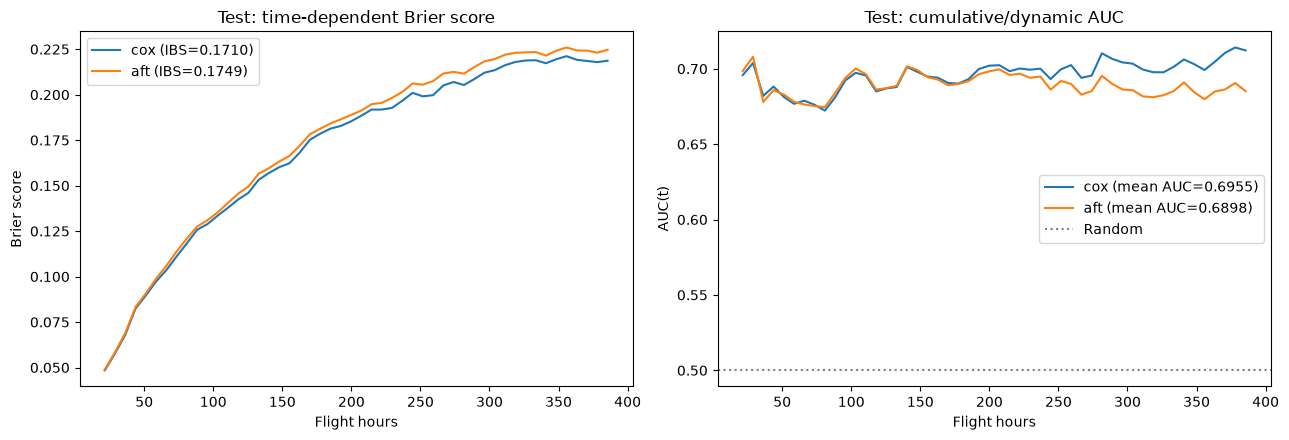

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name in models:
    r = results[(name, "test")]
    axes[0].plot(eval_times, r["brier"], label=f"{name} (IBS={r['ibs']:.4f})")
    axes[1].plot(eval_times, r["auc"], label=f"{name} (mean AUC={r['mean_auc']:.4f})")

axes[0].set(
    title="Test: time-dependent Brier score",
    xlabel="Flight hours",
    ylabel="Brier score",
)
axes[1].axhline(0.5, color="grey", linestyle=":", label="Random")
axes[1].set(
    title="Test: cumulative/dynamic AUC", xlabel="Flight hours", ylabel="AUC(t)"
)
for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

### 5.3 Calibration by prediction decile

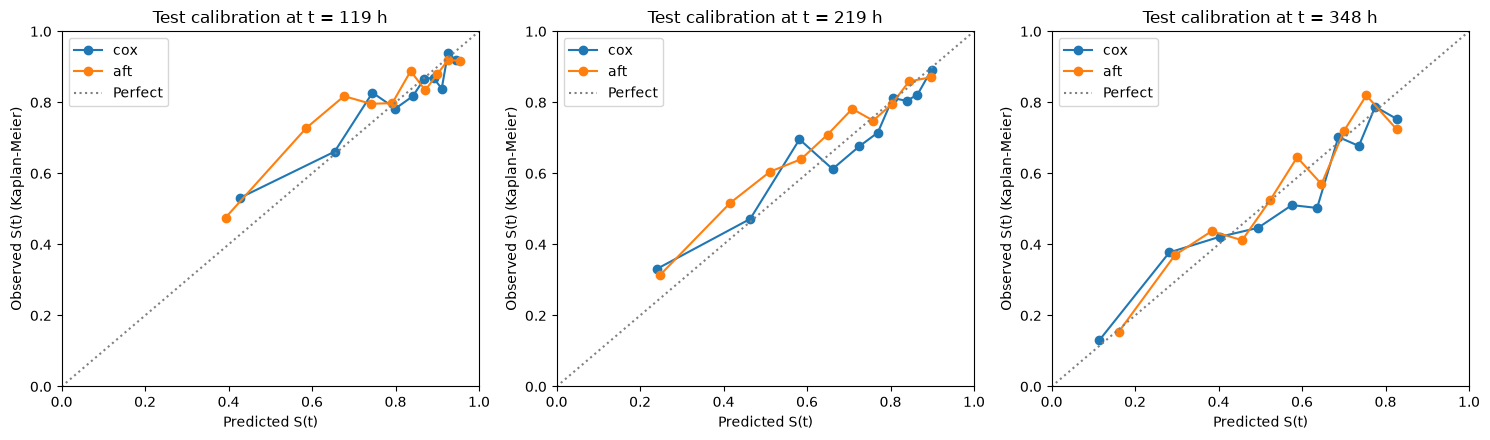

In [17]:
horizons = np.quantile(test["duration_h"], [0.25, 0.5, 0.75])
fig, axes = plt.subplots(1, len(horizons), figsize=(15, 4.5))

for ax, h in zip(axes, horizons):
    for name, model in models.items():
        cal = calibration_curve(model, test, h)
        ax.plot(cal["predicted"], cal["observed"], marker="o", label=name)
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Perfect")
    ax.set(
        title=f"Test calibration at t = {h:.0f} h",
        xlabel="Predicted S(t)",
        ylabel="Observed S(t) (Kaplan-Meier)",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.legend()

plt.tight_layout()
plt.show()

### 5.4 Cox vs AFT: paired bootstrap

In [18]:
# Paired bootstrap on test: both models scored on the same resampled rows
boot_summary, boot_samples = bootstrap_compare(
    models, test, test, eval_times, n_boot=1000, seed=42
)
boot_summary.round(4)

,model_a,model_b,metric,value_a,value_b,diff,ci_low,ci_high,p_value,better,significant
0,cox,aft,c_index,0.6692,0.6698,-0.0006,-0.0102,0.0089,0.936,aft,False
1,cox,aft,c_index_ipcw,0.6645,0.6620,0.0025,-0.0072,0.0121,0.606,cox,False
2,cox,aft,mean_auc,0.6955,0.6898,0.0057,-0.0056,0.0175,0.294,cox,False
3,cox,aft,ibs,0.1710,0.1749,-0.0039,-0.0077,-0.0000,0.048,cox,True


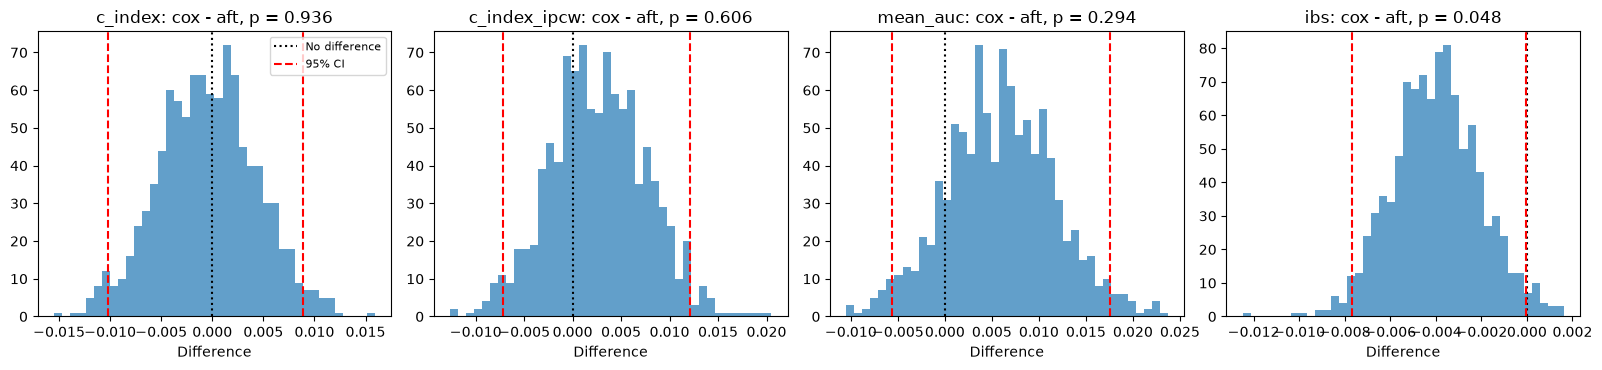

In [19]:
summary = boot_summary.set_index(["model_a", "model_b", "metric"])
a, b = "cox", "aft"

fig, axes = plt.subplots(1, len(SCALAR_METRICS), figsize=(16, 3.8))
for ax, metric in zip(axes, SCALAR_METRICS):
    row = summary.loc[(a, b, metric)]
    ax.hist(boot_samples[(a, metric)] - boot_samples[(b, metric)], bins=40, alpha=0.7)
    ax.axvline(0, color="black", linestyle=":", label="No difference")
    ax.axvline(row["ci_low"], color="red", linestyle="--", label="95% CI")
    ax.axvline(row["ci_high"], color="red", linestyle="--")
    ax.set(title=f"{metric}: {a} - {b}, p = {row['p_value']:.3f}", xlabel="Difference")
axes[0].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 6. Risk factors (SHAP)

### 6.1 Feature importance

In [20]:
# SHAP of the risk score on test: positive values push towards earlier failure.
# Cox is in log-HR units and AFT in log-time units, so compare shares, not raw values.
shap_values = {name: model.explain(test) for name, model in models.items()}

shap_importance = pd.DataFrame(
    {name: np.abs(e.values).mean(axis=0) for name, e in shap_values.items()},
    index=FEATURES,
).sort_values(best_name, ascending=False)
shap_share = shap_importance / shap_importance.sum()

pd.concat({"mean |SHAP|": shap_importance, "share": shap_share}, axis=1).round(4)

mean |SHAP|           share        
                                cox     aft     cox     aft
mean_temp_c                  0.3343  0.2913  0.2050  0.1703
avg_humidity_pct             0.1663  0.2250  0.1019  0.1316
initial_battery_cycles       0.1490  0.1310  0.0914  0.0766
firmware_major               0.1403  0.1777  0.0860  0.1039
environment                  0.1386  0.1807  0.0850  0.1057
hard_landings_per_100h       0.0973  0.1373  0.0597  0.0803
operator_experience_yrs      0.0969  0.1047  0.0594  0.0612
avg_wind_ms                  0.0881  0.0983  0.0540  0.0575
payload_ratio                0.0842  0.0655  0.0516  0.0383
mean_vibration_g             0.0739  0.0571  0.0453  0.0334
avg_payload_kg               0.0554  0.0446  0.0340  0.0261
avg_flight_min               0.0501  0.0454  0.0307  0.0266
maintenance_interval_h       0.0501  0.0400  0.0307  0.0234
daily_utilization_h          0.0456  0.0670  0.0279  0.0392
model                        0.0319  0.0134  0.0196  0.0078
is_refurbished               0.0292  0.0310  0.0179  0.0182

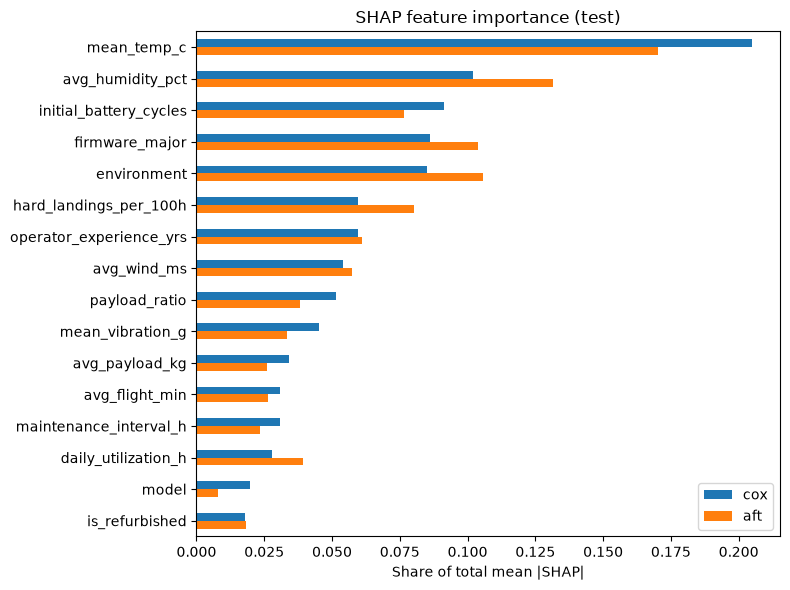

In [21]:
ax = shap_share.plot.barh(figsize=(8, 6))
ax.invert_yaxis()
ax.set(title="SHAP feature importance (test)", xlabel="Share of total mean |SHAP|")
plt.tight_layout()
plt.show()

### 6.2 Direction and shape of the effects

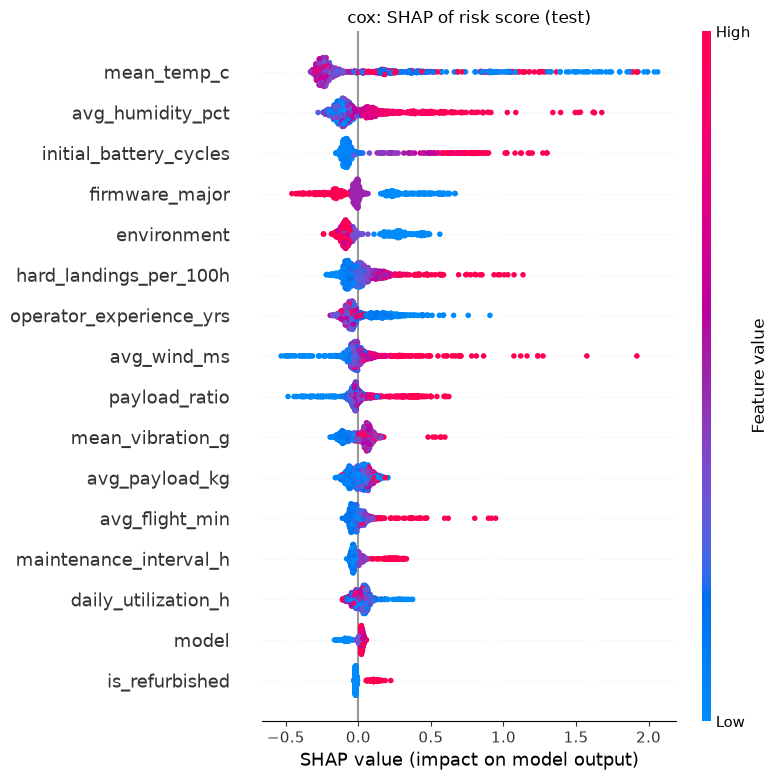

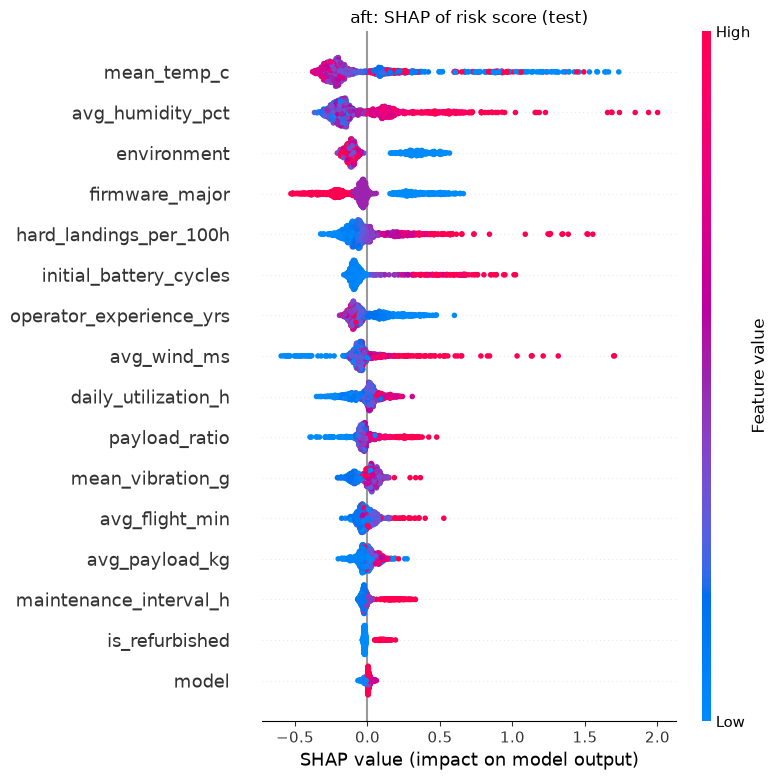

In [22]:
for name, explanation in shap_values.items():
    shap.plots.beeswarm(explanation, max_display=len(FEATURES), show=False)
    plt.title(f"{name}: SHAP of risk score (test)")
    plt.tight_layout()
    plt.show()

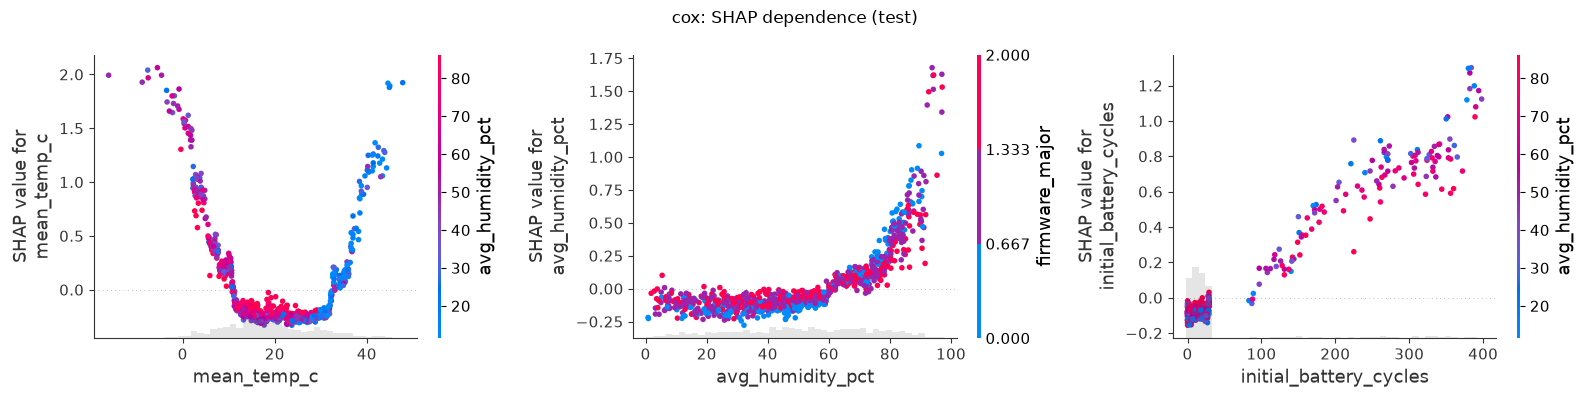

In [23]:
# Dependence plots for the best model's top features (categoricals shown as codes)
top_features = shap_importance.index[:3]
fig, axes = plt.subplots(1, len(top_features), figsize=(16, 4))
for ax, feature in zip(axes, top_features):
    shap.plots.scatter(
        shap_values[best_name][:, feature],
        color=shap_values[best_name],
        ax=ax,
        show=False,
    )
fig.suptitle(f"{best_name}: SHAP dependence (test)")
plt.tight_layout()
plt.show()

## 7. Remaining useful life

### 7.1 Conditional survival S(a + u) / S(a)

Left: fleet level at four ages, Kaplan-Meier vs the best model. Right: one drone at the same ages. The table is the probability of failing within the next 100 h.

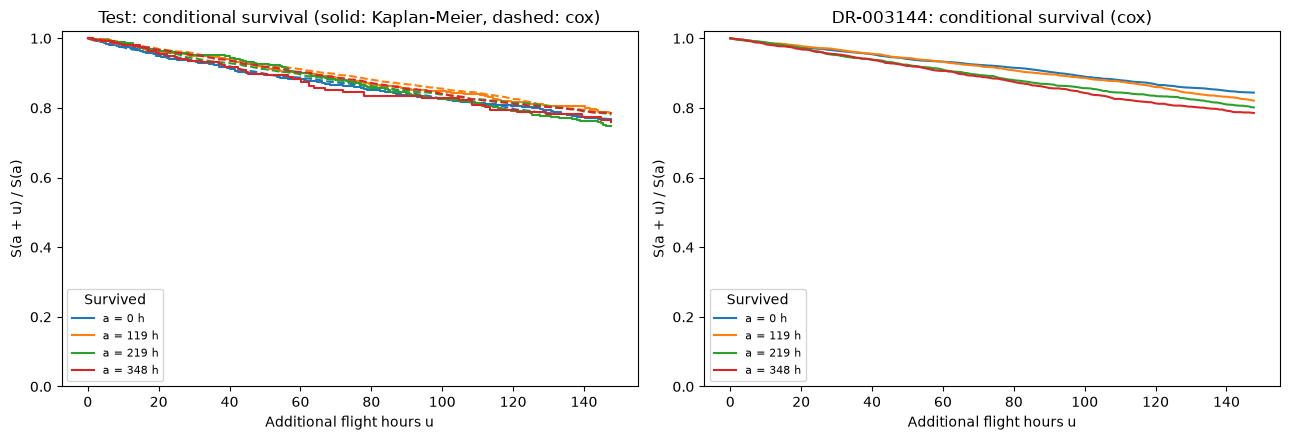

,age_h,observed P(fail in 100 h),cox P(fail in 100 h)
0,0.0,0.175,0.174
1,119.0,0.152,0.144
2,219.0,0.175,0.161
3,348.0,0.171,0.159


In [24]:
# Conditional survival S(a + u | T > a) = S(a + u) / S(a) = exp(-integral of h over
# [a, a + u]): the outlook of a drone that has already flown a hours. A flat hazard
# gives the same curve at every age; a rising one makes older drones' curves fall faster.
# Group level: observed is Kaplan-Meier S(a + u) / S(a); predicted is
# sum S_i(a + u) / sum S_i(a) (drones that failed before a drop out).
cond_ages = np.r_[0.0, np.quantile(test["duration_h"], [0.25, 0.5, 0.75])].round()
cond_grid = np.linspace(0, np.quantile(test["duration_h"], 0.9) - cond_ages[-1], 200)


def km_survival(times: np.ndarray) -> np.ndarray:
    """Test Kaplan-Meier at ``times`` (step function, 1 before the first event)."""
    i = np.searchsorted(km_time, times, side="right") - 1
    return np.where(i >= 0, km_surv[np.maximum(i, 0)], 1.0)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
test_surv = best_model.survival(test, np.r_[cond_ages, np.add.outer(cond_ages, cond_grid).ravel()])
s_age = test_surv[:, : len(cond_ages)].sum(axis=0)
s_ahead = test_surv[:, len(cond_ages) :].sum(axis=0).reshape(len(cond_ages), -1)
window_rows = []
for k, a in enumerate(cond_ages):
    observed = km_survival(a + cond_grid) / km_survival(a)
    predicted = s_ahead[k] / s_age[k]
    ax.step(cond_grid, observed, where="post", color=f"C{k}", label=f"a = {a:.0f} h")
    ax.plot(cond_grid, predicted, color=f"C{k}", linestyle="--")
    window_rows.append(
        {
            "age_h": a,
            f"observed P(fail in {RUL_WINDOW} h)": 1
            - km_survival(a + RUL_WINDOW) / km_survival(a),
            f"{best_name} P(fail in {RUL_WINDOW} h)": 1
            - np.interp(RUL_WINDOW, cond_grid, predicted),
        }
    )
ax.set(
    title=f"Test: conditional survival (solid: Kaplan-Meier, dashed: {best_name})",
    xlabel="Additional flight hours u",
    ylabel="S(a + u) / S(a)",
    ylim=(0, 1.02),
)
ax.legend(title="Survived", fontsize=8)

ax = axes[1]
drone = test.iloc[[idx[0]]]
drone_curves = best_model.conditional_survival(
    pd.concat([drone] * len(cond_ages)), cond_ages, cond_grid
)
for k, (a, s) in enumerate(zip(cond_ages, drone_curves)):
    ax.plot(cond_grid, s, color=f"C{k}", label=f"a = {a:.0f} h")
ax.set(
    title=f"{drone['drone_id'].iloc[0]}: conditional survival ({best_name})",
    xlabel="Additional flight hours u",
    ylabel="S(a + u) / S(a)",
    ylim=(0, 1.02),
)
ax.legend(title="Survived", fontsize=8)

plt.tight_layout()
plt.show()

pd.DataFrame(window_rows).round(3)

### 7.2 Backtest at a landmark

Left: mean predicted conditional survival vs Kaplan-Meier for the test drones still flying at the landmark. Right: predicted vs observed probability of failing within the next 100 h by quintile of the prediction, the quantity behind the maintenance priority. Points below the diagonal mean the model overstates the risk. The dashed line is the best model before the recalibration of section 3 (drawn if it was applied); the bars are the 95% interval of the observed share.

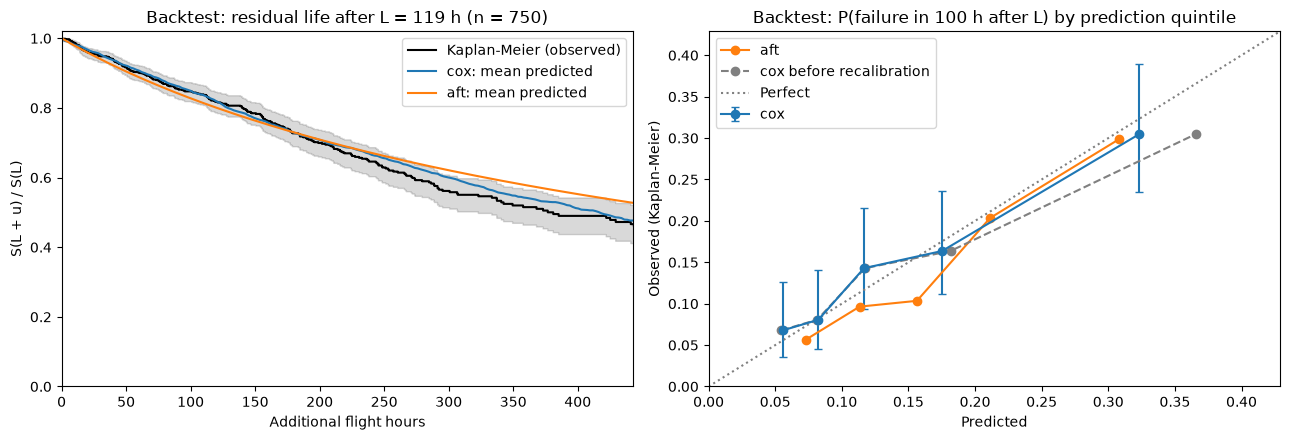

,source,quintile,n,predicted,observed,ci_low,ci_high
0,cox,1,150,0.056,0.068,0.036,0.127
1,cox,2,150,0.082,0.081,0.045,0.141
2,cox,3,150,0.117,0.143,0.093,0.215
3,cox,4,150,0.175,0.164,0.112,0.236
4,cox,5,150,0.323,0.305,0.234,0.390
5,aft,1,150,0.073,0.057,0.027,0.115
6,aft,2,150,0.113,0.096,0.057,0.161
7,aft,3,150,0.156,0.103,0.064,0.166
8,aft,4,150,0.211,0.204,0.145,0.282
9,aft,5,150,0.308,0.299,0.229,0.384


In [25]:
# Backtest: test drones still at risk at landmark L. Their observed residual life
# (Kaplan-Meier) should match the predicted conditional survival, for the whole group
# and inside each quintile of the predicted P(failure in RUL_WINDOW h).
landmark = np.quantile(test["duration_h"], 0.25)
at_risk = test[test["duration_h"] > landmark]
residual = at_risk["duration_h"] - landmark
at_risk_event = at_risk["event"].astype(bool)
at_risk_age = np.full(len(at_risk), landmark)

km_t, km_s, km_ci = kaplan_meier_estimator(at_risk_event, residual, conf_type="log-log")
u = np.linspace(0, residual.quantile(0.9), 200)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.step(km_t, km_s, where="post", color="black", label="Kaplan-Meier (observed)")
ax.fill_between(km_t, km_ci[0], km_ci[1], step="post", color="black", alpha=0.15)
for name, model in models.items():
    pred = model.conditional_survival(at_risk, at_risk_age, u)
    ax.plot(u, pred.mean(axis=0), label=f"{name}: mean predicted")
ax.set(
    title=f"Backtest: residual life after L = {landmark:.0f} h (n = {len(at_risk)})",
    xlabel="Additional flight hours",
    ylabel="S(L + u) / S(L)",
    xlim=(0, u[-1]),
    ylim=(0, 1.02),
)
ax.legend()

ax = axes[1]
# "raw": the best model without the recalibration, to show what it changes
backtest_models = dict(models)
if best_model.calibration is not None:
    backtest_models["raw"] = copy.copy(best_model)
    backtest_models["raw"].calibration = None
group_rows = []
for name, model in backtest_models.items():
    p_fail = 1 - model.conditional_survival(at_risk, at_risk_age, np.array([RUL_WINDOW]))[:, 0]
    quintile = pd.qcut(p_fail, 5, labels=False)
    for q in np.unique(quintile):
        in_group = quintile == q
        group_t, group_s, group_ci = kaplan_meier_estimator(
            at_risk_event[in_group], residual[in_group], conf_type="log-log"
        )
        at_window = np.searchsorted(group_t, RUL_WINDOW, side="right") - 1
        group_rows.append(
            {
                "source": name,
                "quintile": q + 1,
                "n": int(in_group.sum()),
                "predicted": p_fail[in_group].mean(),
                "observed": 1 - group_s[at_window],
                "ci_low": 1 - group_ci[1][at_window],
                "ci_high": 1 - group_ci[0][at_window],
            }
        )
backtest_groups = pd.DataFrame(group_rows)
for name, rows in backtest_groups.groupby("source", sort=False):
    if name == "raw":
        ax.plot(
            rows["predicted"],
            rows["observed"],
            marker="o",
            color="grey",
            linestyle="--",
            label=f"{best_name} before recalibration",
        )
    elif name == best_name:
        ax.errorbar(
            rows["predicted"],
            rows["observed"],
            yerr=[rows["observed"] - rows["ci_low"], rows["ci_high"] - rows["observed"]],
            marker="o",
            capsize=3,
            label=name,
        )
    else:
        ax.plot(rows["predicted"], rows["observed"], marker="o", label=name)
top = 1.1 * backtest_groups[["predicted", "ci_high"]].to_numpy().max()
ax.plot([0, top], [0, top], color="grey", linestyle=":", label="Perfect")
ax.set(
    title=f"Backtest: P(failure in {RUL_WINDOW} h after L) by prediction quintile",
    xlabel="Predicted",
    ylabel="Observed (Kaplan-Meier)",
    xlim=(0, top),
    ylim=(0, top),
)
ax.legend()

plt.tight_layout()
plt.show()

backtest_groups.round(3)

### 7.3 Drones in service

Forecast for the test drones in service at the data cut-off (section 2). The horizon keeps age + horizon inside the Cox baseline support. The far end of that support rests on few training drones (printed below), so long-horizon figures for the oldest drones are noisy.

In [26]:
# Drones in service at the data cut-off; current age = duration_h
active = test[test["in_service"]]

# Keep age + horizon inside the Cox baseline support (flat after the last training event)
last_train_event = train.loc[train["event"] == 1, "duration_h"].max()
horizon = np.floor(last_train_event - active["duration_h"].max())

rul = remaining_life(best_model, active, horizon=horizon, window=RUL_WINDOW)
print(f"Model: {best_name}, horizon: {horizon:.0f} h, drones in service: {len(rul)}")

support = np.array([0.5, 0.75, 1.0]) * last_train_event
still_flying = [int((train["duration_h"] >= t).sum()) for t in support]
print(f"Training drones still at risk at {support.round().tolist()} h: {still_flying}")
rul.sort_values("p_fail_window", ascending=False).head(10).round(3)

Model: cox, horizon: 1111 h, drones in service: 500
Training drones still at risk at [1174.0, 1761.0, 2348.0] h: [124, 20, 4]


,drone_id,age_h,rul_q10,rul_median,rmrl,p_fail_window
3057,DR-003057,193.50,9.999,69.993,114.093,0.625
751,DR-000751,59.10,13.332,67.771,109.115,0.619
2313,DR-002313,63.45,14.443,81.103,123.953,0.572
2709,DR-002709,336.16,17.776,91.102,151.016,0.540
434,DR-000434,199.29,16.665,89.991,147.963,0.539
3616,DR-003616,145.55,16.665,99.990,155.745,0.502
2367,DR-002367,227.76,14.443,106.656,170.475,0.487
3580,DR-003580,463.74,19.998,107.767,186.633,0.472
1244,DR-001244,53.76,22.220,108.878,159.752,0.471
3430,DR-003430,186.20,17.776,109.989,176.802,0.468


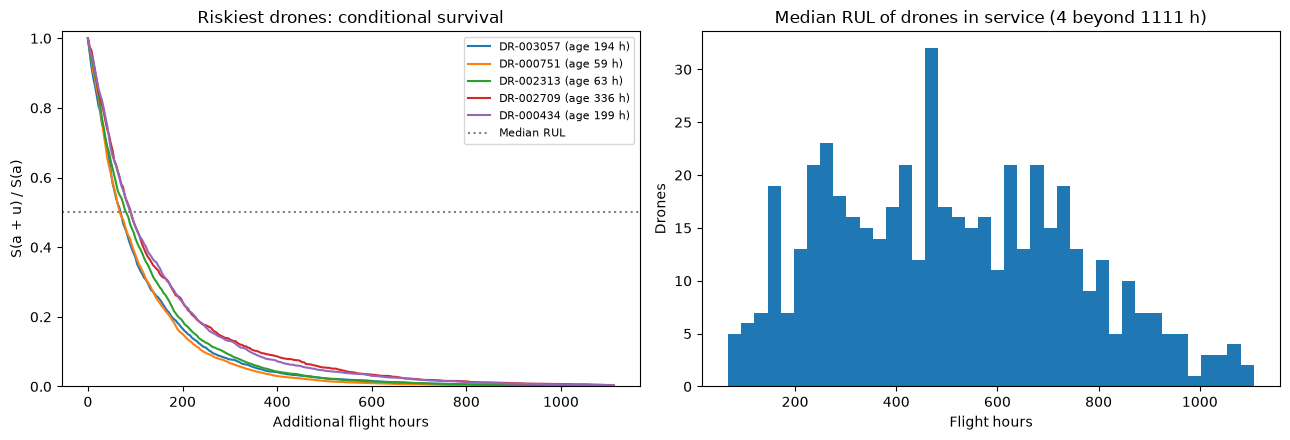

In [27]:
rul_grid = np.linspace(0, horizon, 300)
riskiest = rul.nlargest(5, "p_fail_window").index
rul_curves = best_model.conditional_survival(
    active.loc[riskiest], active.loc[riskiest, "duration_h"], rul_grid
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
for k, (i, s) in enumerate(zip(riskiest, rul_curves)):
    label = f"{active.at[i, 'drone_id']} (age {active.at[i, 'duration_h']:.0f} h)"
    ax.plot(rul_grid, s, color=f"C{k}", label=label)
ax.axhline(0.5, color="grey", linestyle=":", label="Median RUL")
ax.set(
    title="Riskiest drones: conditional survival",
    xlabel="Additional flight hours",
    ylabel="S(a + u) / S(a)",
    ylim=(0, 1.02),
)
ax.legend(fontsize=8)

ax = axes[1]
finite = np.isfinite(rul["rul_median"])
ax.hist(rul.loc[finite, "rul_median"], bins=40)
ax.set(
    title=f"Median RUL of drones in service ({(~finite).sum()} beyond {horizon:.0f} h)",
    xlabel="Flight hours",
    ylabel="Drones",
)

plt.tight_layout()
plt.show()

## 8. Artifacts for the dashboards

In [28]:
# Persist everything the dashboard needs; the fitted models are already in MODELS_DIR.
os.makedirs(ARTIFACTS_DIR, exist_ok=True)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_parquet(os.path.join(ARTIFACTS_DIR, f"{name}.parquet"), index=False)


save_table(metrics.reset_index(), "metrics")

save_table(
    pd.concat(
        pd.DataFrame(
            {
                "model": name,
                "t": eval_times,
                "brier": results[(name, "test")]["brier"],
                "auc": results[(name, "test")]["auc"],
            }
        )
        for name in models
    ),
    "brier_auc",
)

save_table(
    pd.concat(
        calibration_curve(model, test, h).assign(model=name, horizon=h)
        for name, model in models.items()
        for h in horizons
    ),
    "calibration",
)

save_table(boot_summary, "bootstrap_summary")
save_table(
    pd.concat(
        pd.DataFrame(
            {
                "iteration": boot_samples.index,
                "model": model_name,
                "metric": metric,
                "value": boot_samples[(model_name, metric)].to_numpy(),
            }
        )
        for model_name, metric in boot_samples.columns
    ),
    "bootstrap_samples",
)

# SHAP in long format: one row per (drone, model, feature)
n_features = len(FEATURES)
save_table(
    pd.concat(
        pd.DataFrame(
            {
                "drone_id": np.repeat(test["drone_id"].to_numpy(), n_features),
                "model": name,
                "feature": np.tile(e.feature_names, len(test)),
                "shap": e.values.ravel(),
                "value": e.data.ravel(),
                "display": test[e.feature_names].astype(str).to_numpy().ravel(),
            }
        )
        for name, e in shap_values.items()
    ),
    "shap_values",
)
importance = shap_importance.reset_index(names="feature").melt(
    id_vars="feature", var_name="model", value_name="mean_abs_shap"
)
importance["share"] = importance["mean_abs_shap"] / importance.groupby("model")[
    "mean_abs_shap"
].transform("sum")
save_table(importance, "shap_importance")

# Per-drone predictions. risk_group: terciles of the best model's risk over all test
# drones; priority: maintenance urgency of drones in service by p_fail_window
# (drones that failed or left the fleet have none).
PRIORITY_HIGH, PRIORITY_MEDIUM = 0.5, 0.2
predictions = test.copy()
for name, model in models.items():
    predictions[f"risk_{name}"] = model.risk(test)
predictions["risk_group"] = pd.qcut(
    predictions[f"risk_{best_name}"], 3, labels=["Low", "Medium", "High"]
).astype(str)
predictions = predictions.join(rul.drop(columns=["drone_id"]))
predictions["priority"] = np.select(
    [
        predictions["p_fail_window"] >= PRIORITY_HIGH,
        predictions["p_fail_window"] >= PRIORITY_MEDIUM,
        predictions["p_fail_window"].notna(),
        predictions["event"] == 1,
    ],
    ["High", "Medium", "Low", "None (failed)"],
    default="None (left the fleet)",
)
save_table(predictions, "predictions")

# Mean predicted survival vs Kaplan-Meier on test, and the landmark backtest.
# Kaplan-Meier is recomputed here because later cells reuse the km_* names.
km_test = kaplan_meier_estimator(
    test["event"].astype(bool), test["duration_h"], conf_type="log-log"
)
km_backtest = kaplan_meier_estimator(
    at_risk["event"].astype(bool), residual, conf_type="log-log"
)
save_table(
    pd.concat(
        [
            pd.DataFrame(
                {
                    "source": "km",
                    "t": km_test[0],
                    "s": km_test[1],
                    "ci_low": km_test[2][0],
                    "ci_high": km_test[2][1],
                }
            ),
            *(
                pd.DataFrame({"source": name, "t": grid, "s": s.mean(axis=0)})
                for name, s in curves.items()
            ),
        ]
    ),
    "survival_mean",
)
save_table(
    pd.concat(
        [
            pd.DataFrame(
                {
                    "source": "km",
                    "u": km_backtest[0],
                    "s": km_backtest[1],
                    "ci_low": km_backtest[2][0],
                    "ci_high": km_backtest[2][1],
                }
            ),
            *(
                pd.DataFrame(
                    {
                        "source": name,
                        "u": u,
                        "s": model.conditional_survival(
                            at_risk, np.full(len(at_risk), landmark), u
                        ).mean(axis=0),
                    }
                )
                for name, model in models.items()
            ),
        ]
    ),
    "backtest",
)
save_table(backtest_groups, "backtest_groups")

numeric_features = [f for f in FEATURES if f not in cats and f != "is_refurbished"]
meta = {
    "generated_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    "best_name": best_name,
    "models": {name: f"best_{name}.json" for name in models},
    "features": FEATURES,
    "cat_features": CAT_FEATURES,
    "categories": cats,
    "numeric_ranges": {
        f: [float(train[f].min()), float(train[f].max())] for f in numeric_features
    },
    "split": {"t_val": str(t_val.date()), "t_test": str(t_test.date())},
    "n_trials": N_TRIALS,
    "n_boot": len(boot_samples),
    "eval_times": {name: eval_times.tolist() for name in splits},
    "calibration_horizons": [float(h) for h in horizons],
    "rul_horizon": float(horizon),
    "rul_window": RUL_WINDOW,
    "landmark": float(landmark),
    "priority_thresholds": {"high": PRIORITY_HIGH, "medium": PRIORITY_MEDIUM},
    "shap_base": {name: float(e.base_values[0]) for name, e in shap_values.items()},
}
with open(os.path.join(ARTIFACTS_DIR, "meta.json"), "w") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

sorted(os.listdir(ARTIFACTS_DIR))

['backtest.parquet',
 'backtest_groups.parquet',
 'bootstrap_samples.parquet',
 'bootstrap_summary.parquet',
 'brier_auc.parquet',
 'calibration.parquet',
 'meta.json',
 'metrics.parquet',
 'predictions.parquet',
 'shap_importance.parquet',
 'shap_values.parquet',
 'survival_mean.parquet']